In [1]:
import numpy as np
import s3fs
import pygrib
import gzip
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
from scipy.ndimage import gaussian_filter
from cartopy.io.img_tiles import GoogleTiles
import pandas as pd
from tqdm import tqdm
from os.path import join
import geopandas as gpd
from shapely.geometry import Point
%matplotlib inline

In [2]:
grib_table_url = "https://raw.githubusercontent.com/NOAA-National-Severe-Storms-Laboratory/mrms-support/refs/heads/main/GRIB2_TABLES/UserTable_MRMS_v12.2.csv"
grib_table = pd.read_csv(grib_table_url)


def load_mrms_data(datetime, variable, region="CONUS"):
    ts = pd.Timestamp(datetime)
    ts_date_str = ts.strftime("%Y%m%d")
    ts_datetime_str = ts.strftime("%Y%m%d-%H%M%S")
    # s3 = s3fs.S3FileSystem(anon=True)
    filename = f"s3://noaa-mrms-pds/{region}/{variable}/{ts_date_str}/MRMS_{variable}_{ts_datetime_str}.grib2.gz"
    with s3.open(filename, "rb") as f:
        f_data = f.read()
    data = pygrib.fromstring(gzip.decompress(f_data))
    grib_attrs = grib_table.loc[(grib_table["Category"] == data["parameterCategory"]) & (grib_table["Parameter"] == data["parameterNumber"])].T.iloc[:, 0].dropna().to_dict()
    xr_data = xr.DataArray(np.expand_dims(data.values[::-1], axis=0), coords={"time": [datetime], "lat":data.latitudes[::data.Nx][::-1], "lon":data.longitudes[:data.Nx], 
                                                }, 
                           name=variable,
                           attrs=grib_attrs)
    return xr_data

In [18]:
dates = pd.date_range("2024-03-16 00:00", "2024-04-29 00:00", freq="1h")
time_steps = []
s3 = s3fs.S3FileSystem(anon=True)
for date in tqdm(dates):
    try:
        mrms_full_step = load_mrms_data(date, "MultiSensor_QPE_01H_Pass2_00.00")
    except Exception as e:
        print(f"Error finding file for date: {date}")
        continue
        
    time_steps.append(mrms_full_step.sel(lon=slice(360-124.7, 360-113.9, None), lat=slice(32.3, 42.1, None)))

  9%|▊         | 91/1057 [01:15<07:51,  2.05it/s]

Error finding file for date: 2024-03-19 17:00:00
Error finding file for date: 2024-03-19 18:00:00


  9%|▊         | 92/1057 [01:15<06:01,  2.67it/s]

Error finding file for date: 2024-03-19 19:00:00


100%|██████████| 1057/1057 [23:31<00:00,  1.34s/it] 


In [19]:
%%time
combined = xr.concat(time_steps, dim="time")

CPU times: user 5.29 s, sys: 36.3 s, total: 41.6 s
Wall time: 3min 54s


In [21]:
%%time
combined.to_netcdf('/glade/derecho/scratch/cbecker/MRMS_CAT_Daily_2024.nc')

CPU times: user 195 ms, sys: 5.81 s, total: 6 s
Wall time: 12.3 s


In [3]:
%%time
ds = xr.open_dataset('/glade/derecho/scratch/cbecker/MRMS_CAT_Daily_2024.nc').load()

CPU times: user 893 ms, sys: 6.15 s, total: 7.05 s
Wall time: 28.1 s


In [4]:
gdf = gpd.read_file('/glade/derecho/scratch/cbecker/California_County_Boundaries_6550485670014028237.geojson')

In [5]:
sb = gdf[gdf['COUNTY_NAME'] == 'Santa Barbara']['geometry'].iloc[0]
ventura = gdf[gdf['COUNTY_NAME'] == 'Ventura']['geometry'].iloc[0]
la = gdf[gdf['COUNTY_NAME'] == 'Los Angeles']['geometry'].iloc[0]

In [6]:
%%time
lon, lat = np.meshgrid(ds.lon, ds.lat)
lon = ((lon + 180) % 360) - 180
data_arrays = []
for name, polygon in zip(['Santa Barbara', 'Ventura', 'Los Angeles'], [sb, ventura, la]):
    
    points = [Point(x, y) for x, y in zip(lon.ravel(), lat.ravel())]
    mask = np.array([polygon.contains(pt) for pt in points]).reshape(lon.shape)
    print(mask.sum())
    # Apply mask
    da_masked = ds.where(mask)
    data_arrays.append(da_masked)

6510
4627
10011
CPU times: user 31.7 s, sys: 2.46 s, total: 34.2 s
Wall time: 34.3 s


In [7]:
masked_ds = xr.concat([x for x in data_arrays], dim='county').assign_coords(county=['Santa Barbara', 'Ventura', 'Los Angeles']).load().rename({'MultiSensor_QPE_01H_Pass2_00.00':'precip_acc_1h'})
daily_1h_max = masked_ds.groupby(masked_ds['time'].dt.date).max().max(['lat', 'lon'])
daily_max = masked_ds.groupby(masked_ds['time'].dt.date).sum().max(['lat', 'lon'])

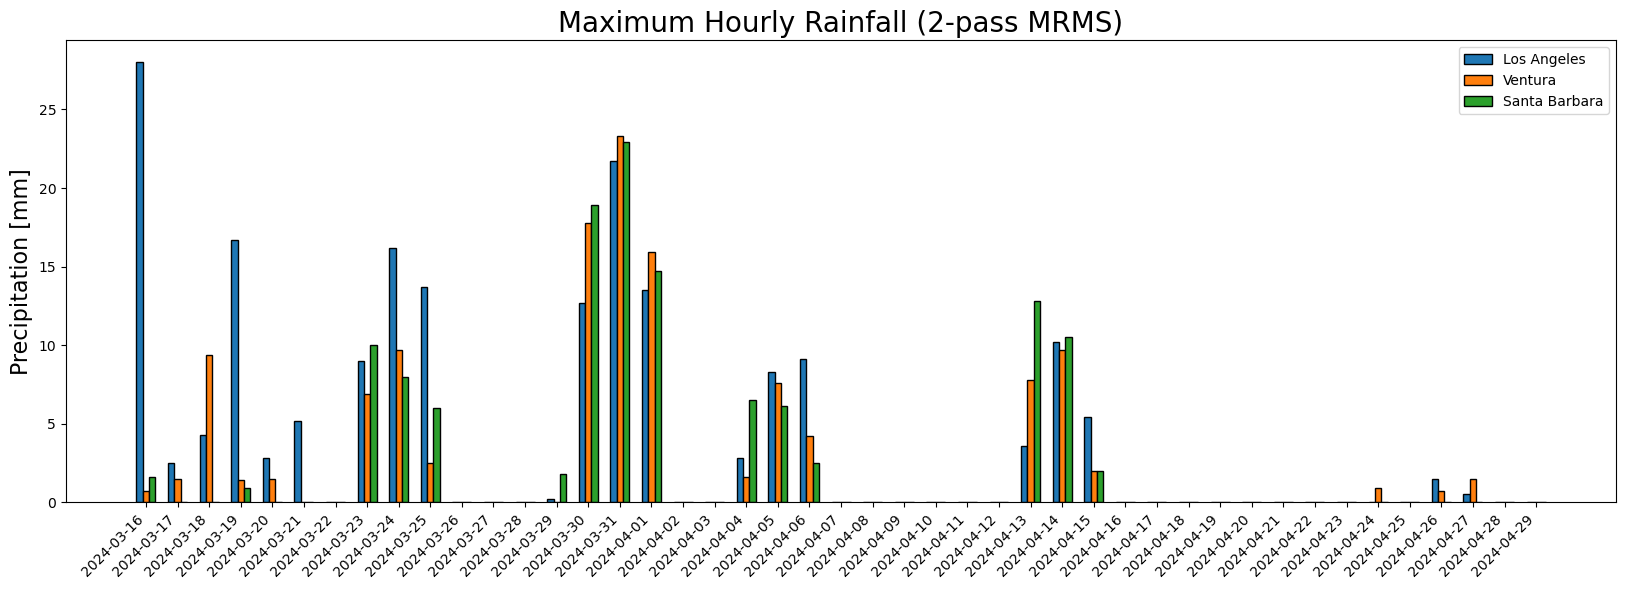

In [8]:
fig, ax = plt.subplots(figsize=(20, 6))
x = np.arange(len(daily_1h_max['date']))
width = 0.20
ax.bar(x - width, daily_1h_max.sel(county='Los Angeles')['precip_acc_1h'], width, edgecolor='k', label='Los Angeles')
ax.bar(x, daily_1h_max.sel(county='Ventura')['precip_acc_1h'], width, edgecolor='k', label='Ventura')
ax.bar(x + width, daily_1h_max.sel(county='Santa Barbara')['precip_acc_1h'], width, edgecolor='k', label='Santa Barbara')

ax.set_xticks(x)
ax.set_xticklabels(pd.to_datetime(daily_1h_max['date']).strftime("%Y-%m-%d"), rotation=45, ha="right")

ax.set_ylabel("Precipitation [mm]", fontsize=16)
ax.set_title("Maximum Hourly Rainfall (2-pass MRMS)", fontsize=20)
ax.legend()

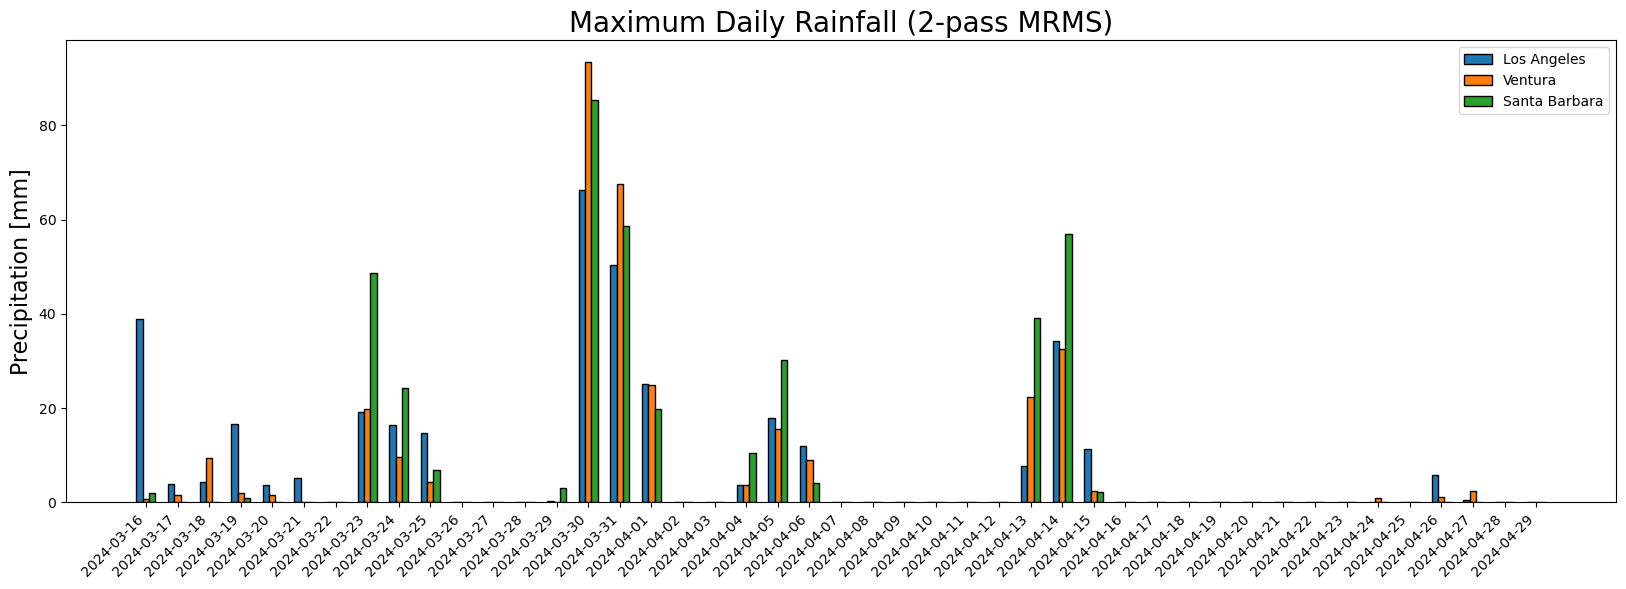

In [9]:
fig, ax = plt.subplots(figsize=(20, 6))
x = np.arange(len(daily_max['date']))
width = 0.20
ax.bar(x - width, daily_max.sel(county='Los Angeles')['precip_acc_1h'], width, edgecolor='k', label='Los Angeles')
ax.bar(x, daily_max.sel(county='Ventura')['precip_acc_1h'], width, edgecolor='k', label='Ventura')
ax.bar(x + width, daily_max.sel(county='Santa Barbara')['precip_acc_1h'], width, edgecolor='k', label='Santa Barbara')

ax.set_xticks(x)
ax.set_xticklabels(pd.to_datetime(daily_max['date']).strftime("%Y-%m-%d"), rotation=45, ha="right")

ax.set_ylabel("Precipitation [mm]", fontsize=16)
ax.set_title("Maximum Daily Rainfall (2-pass MRMS)", fontsize=20)
ax.legend()

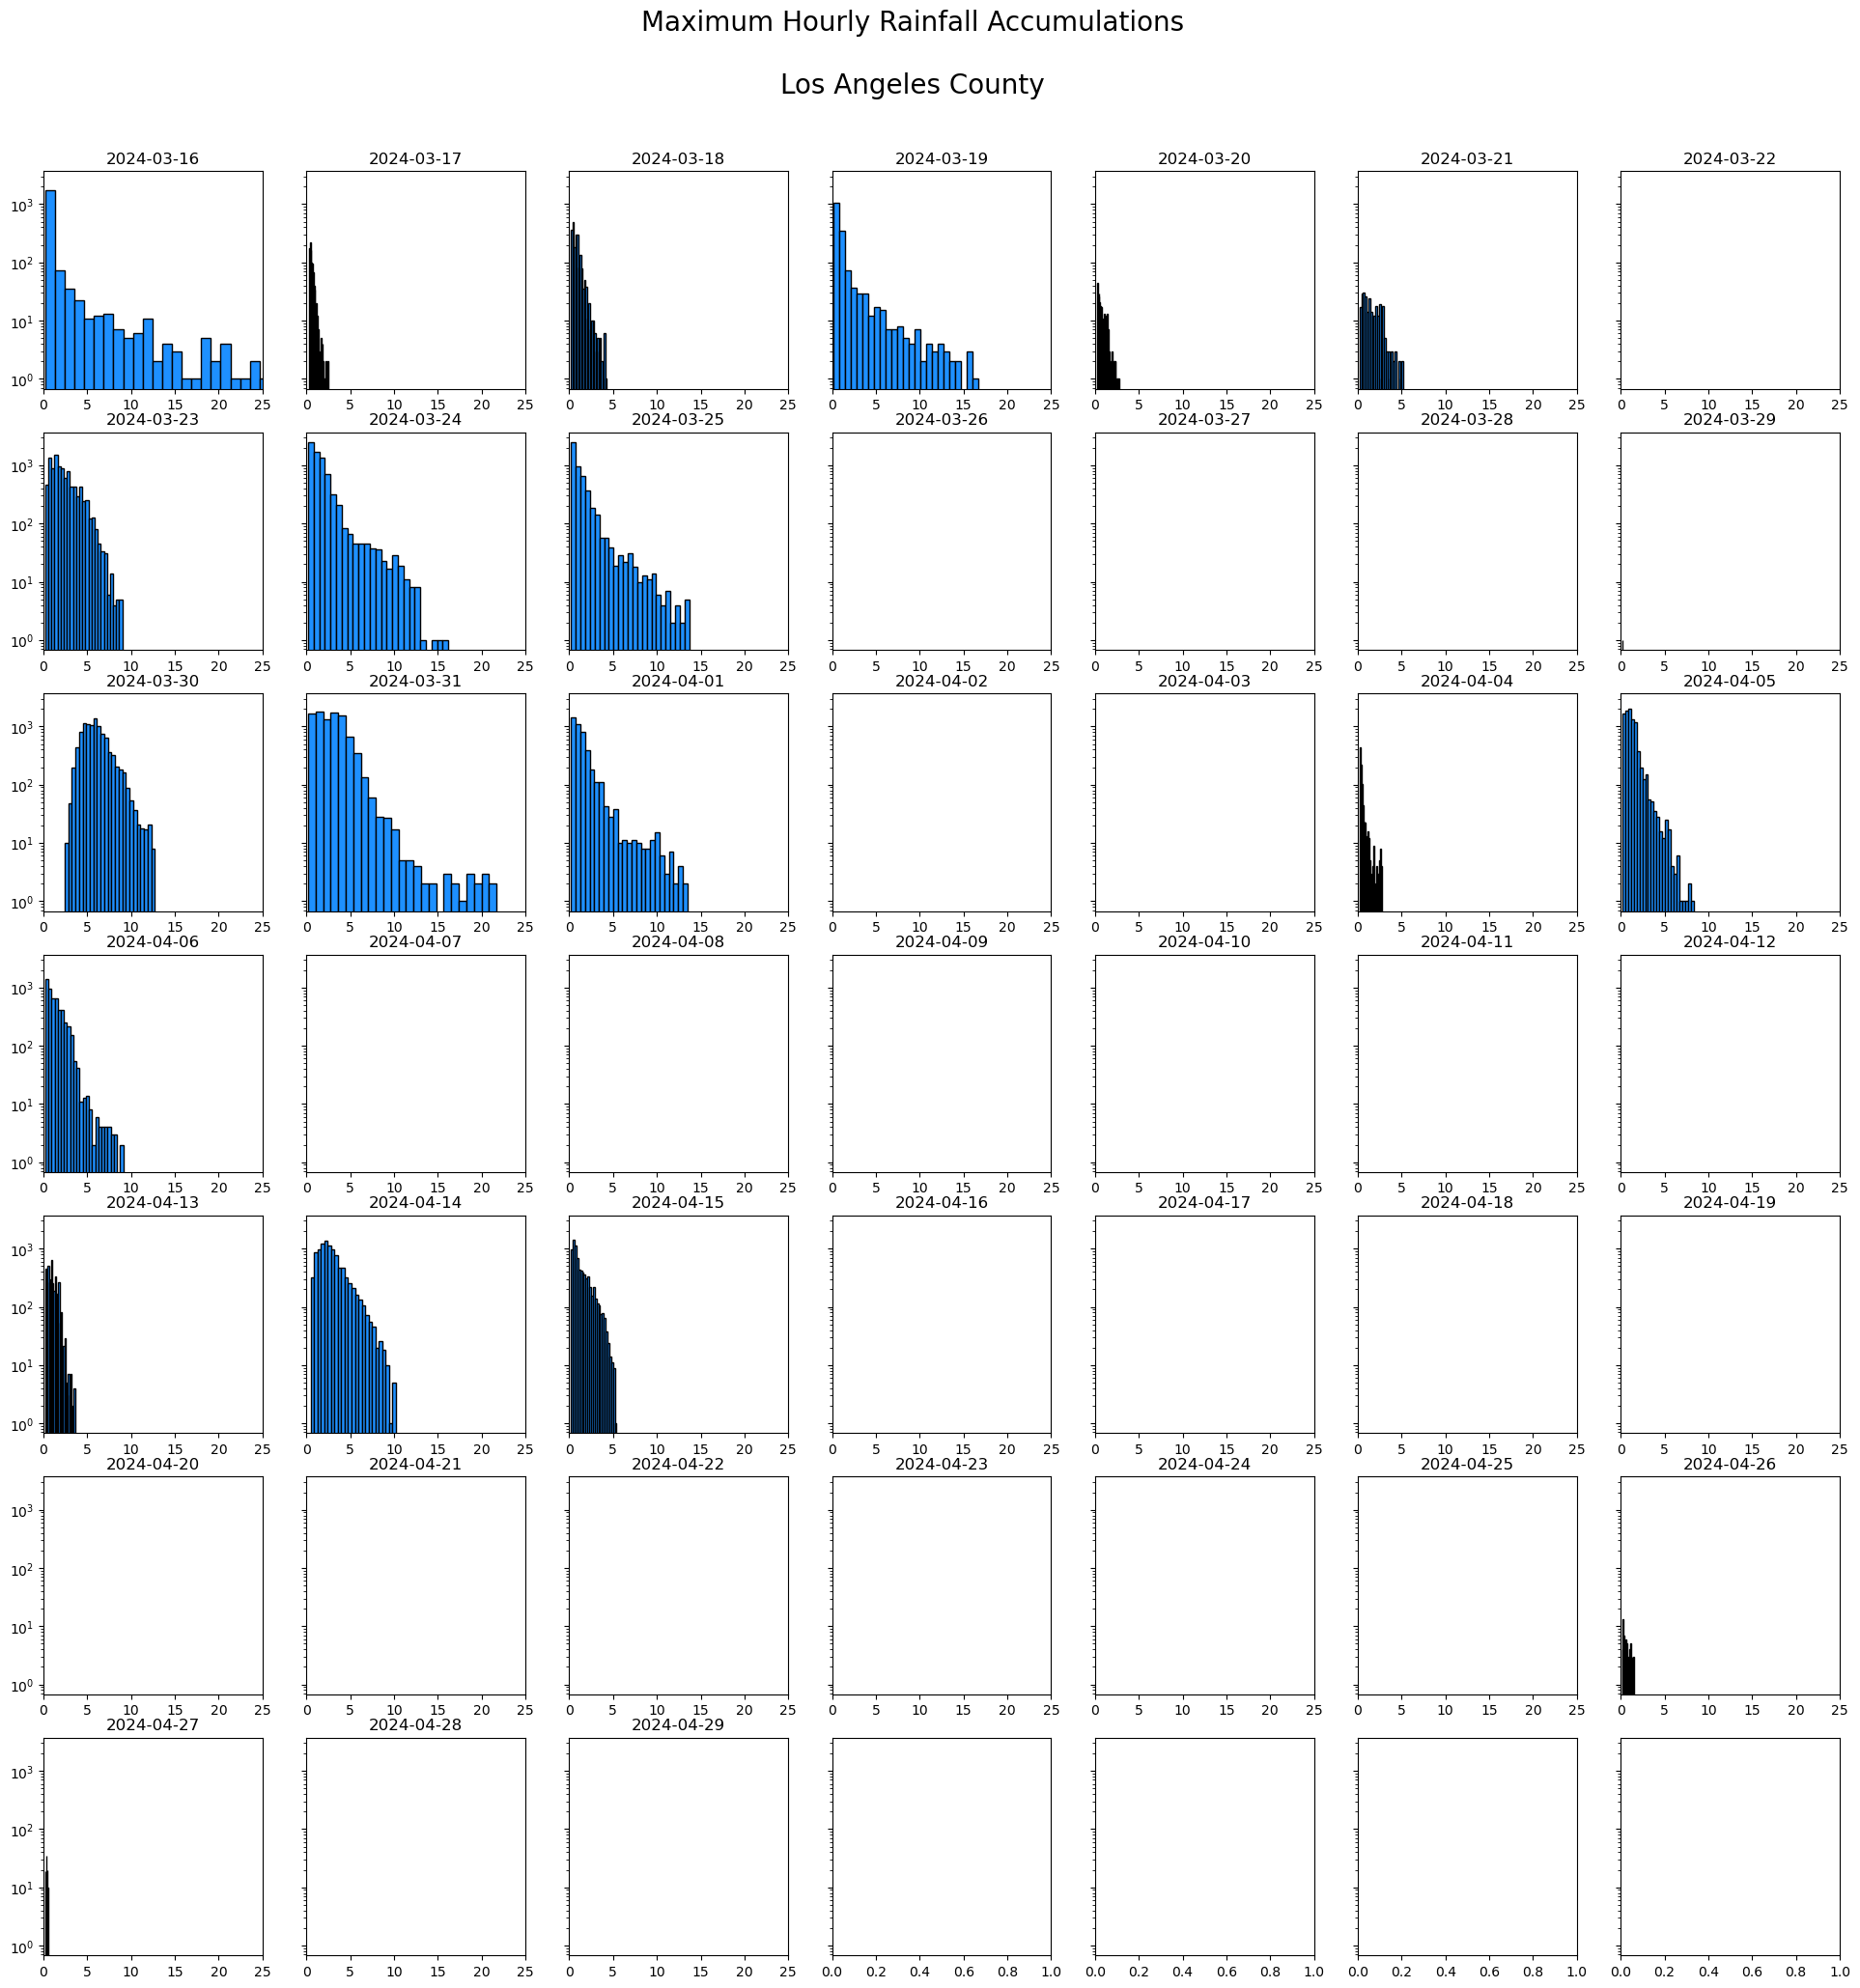

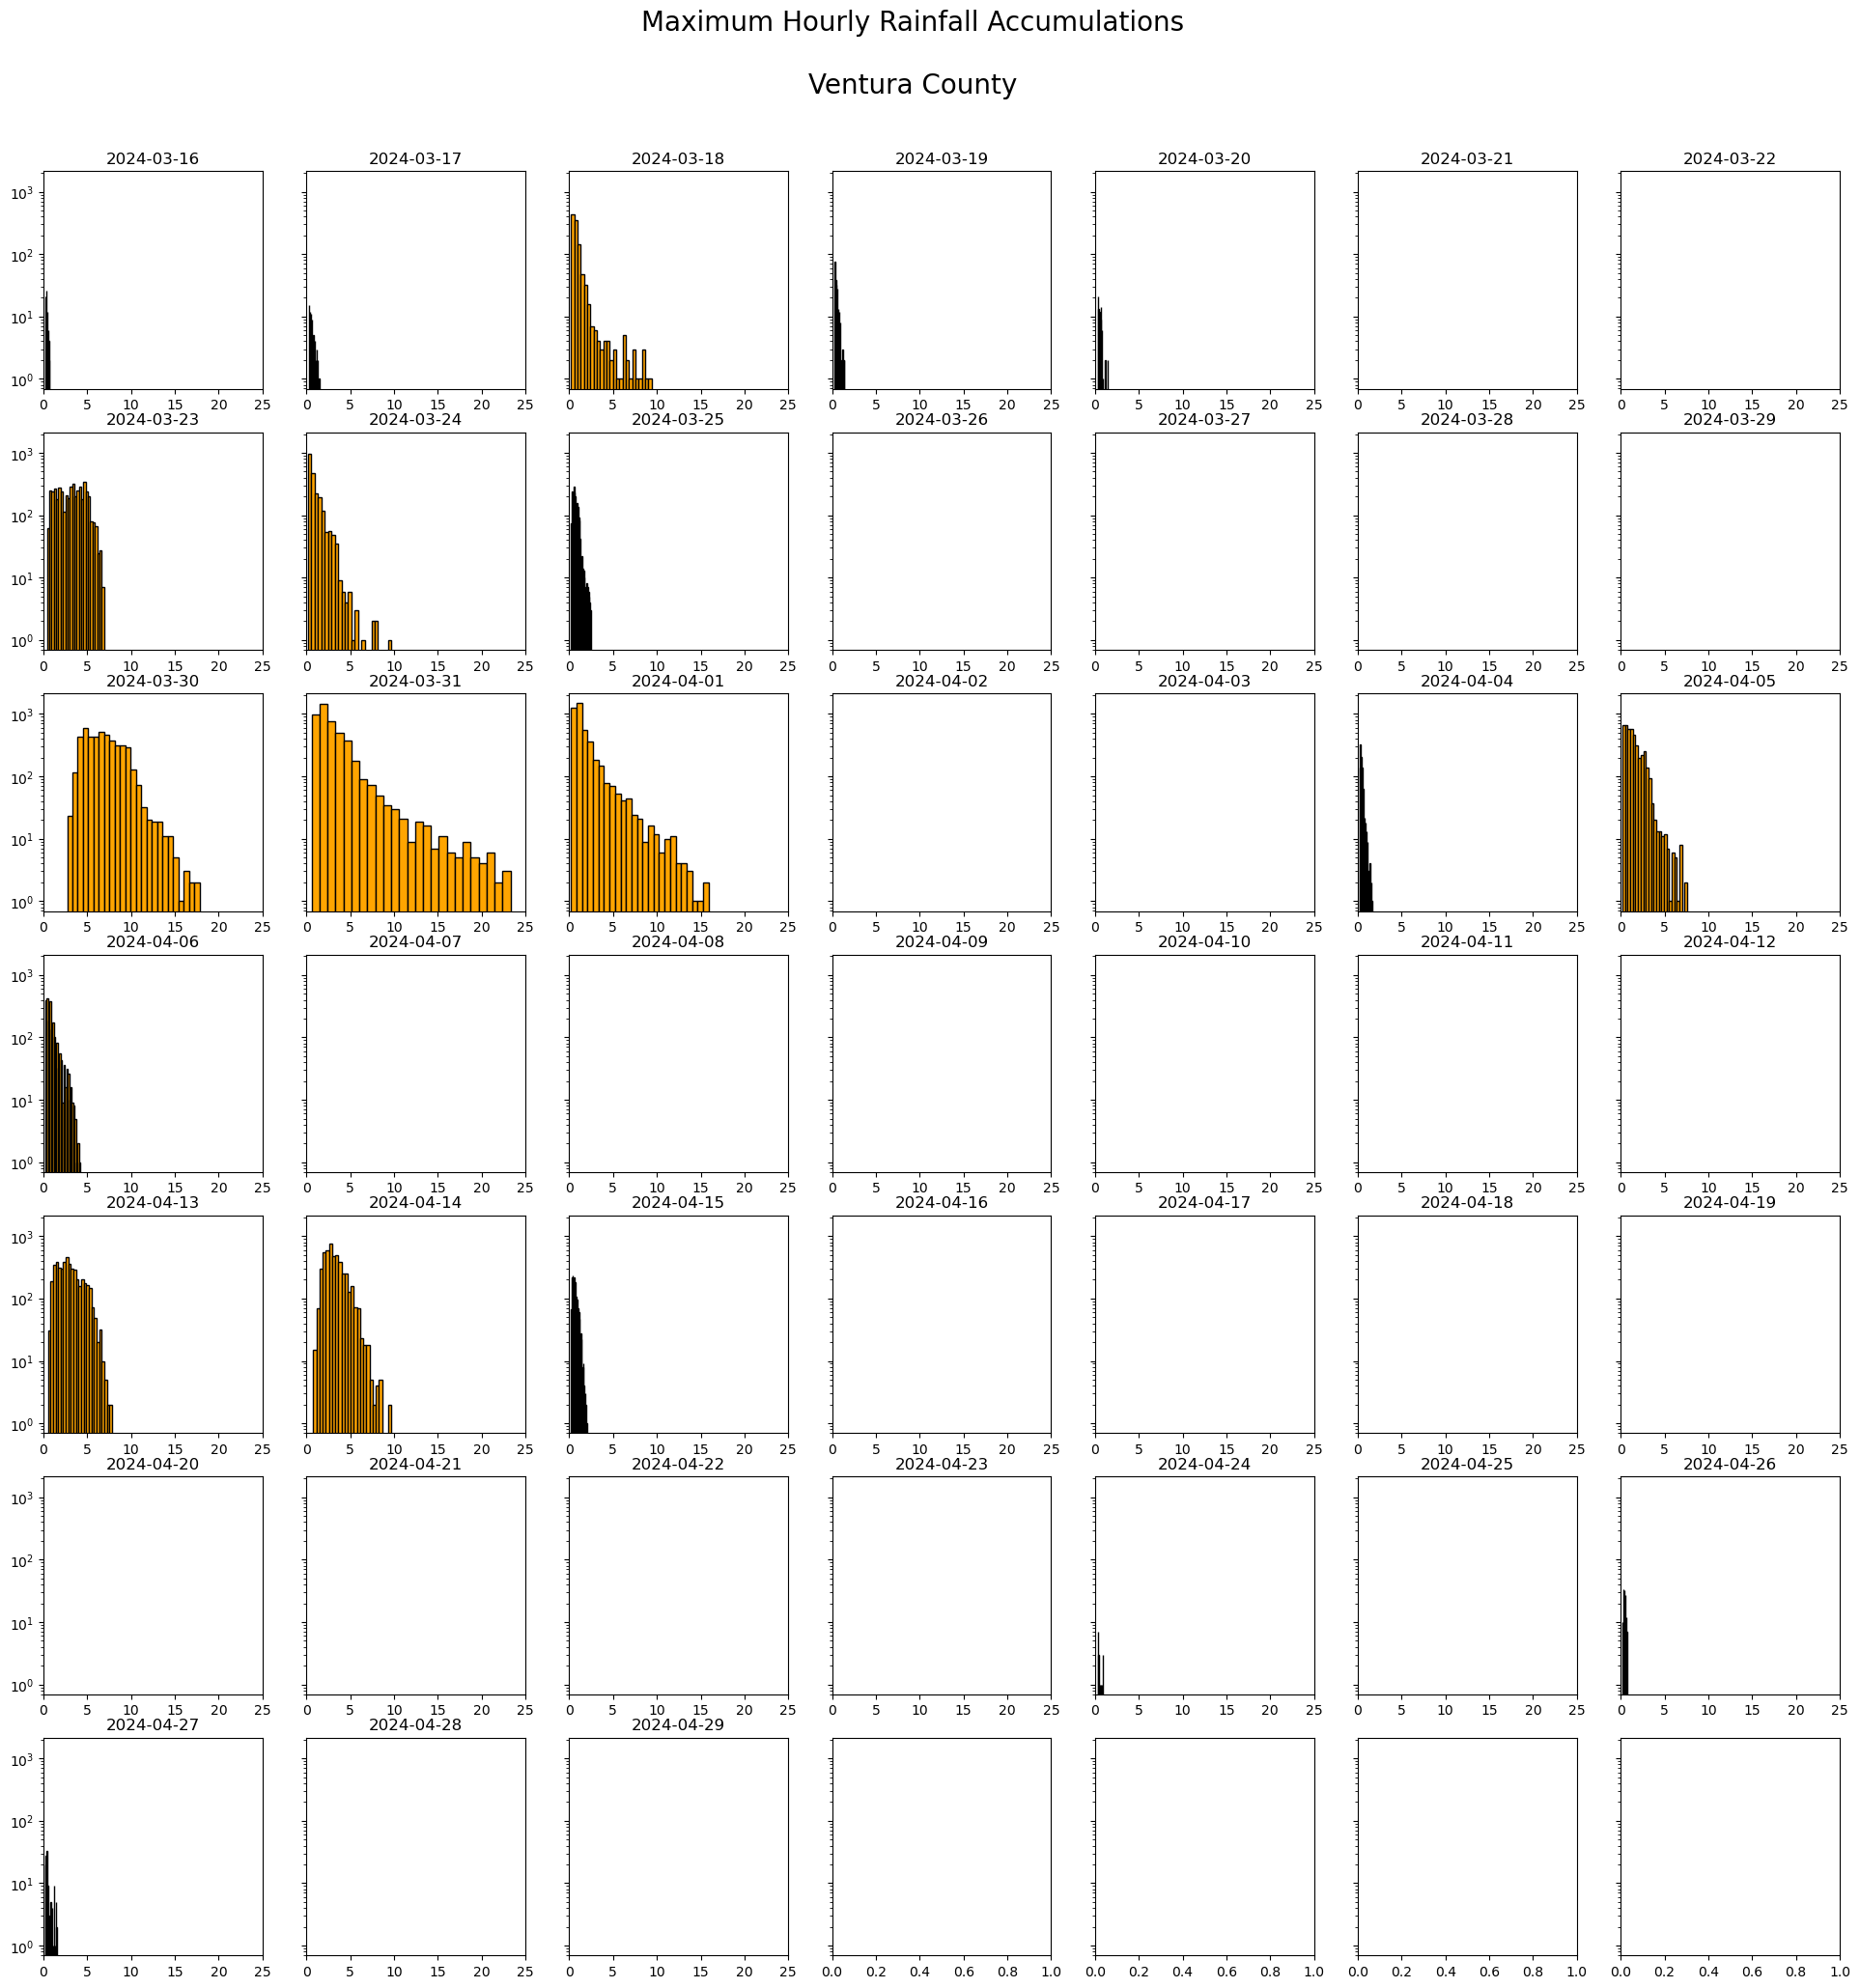

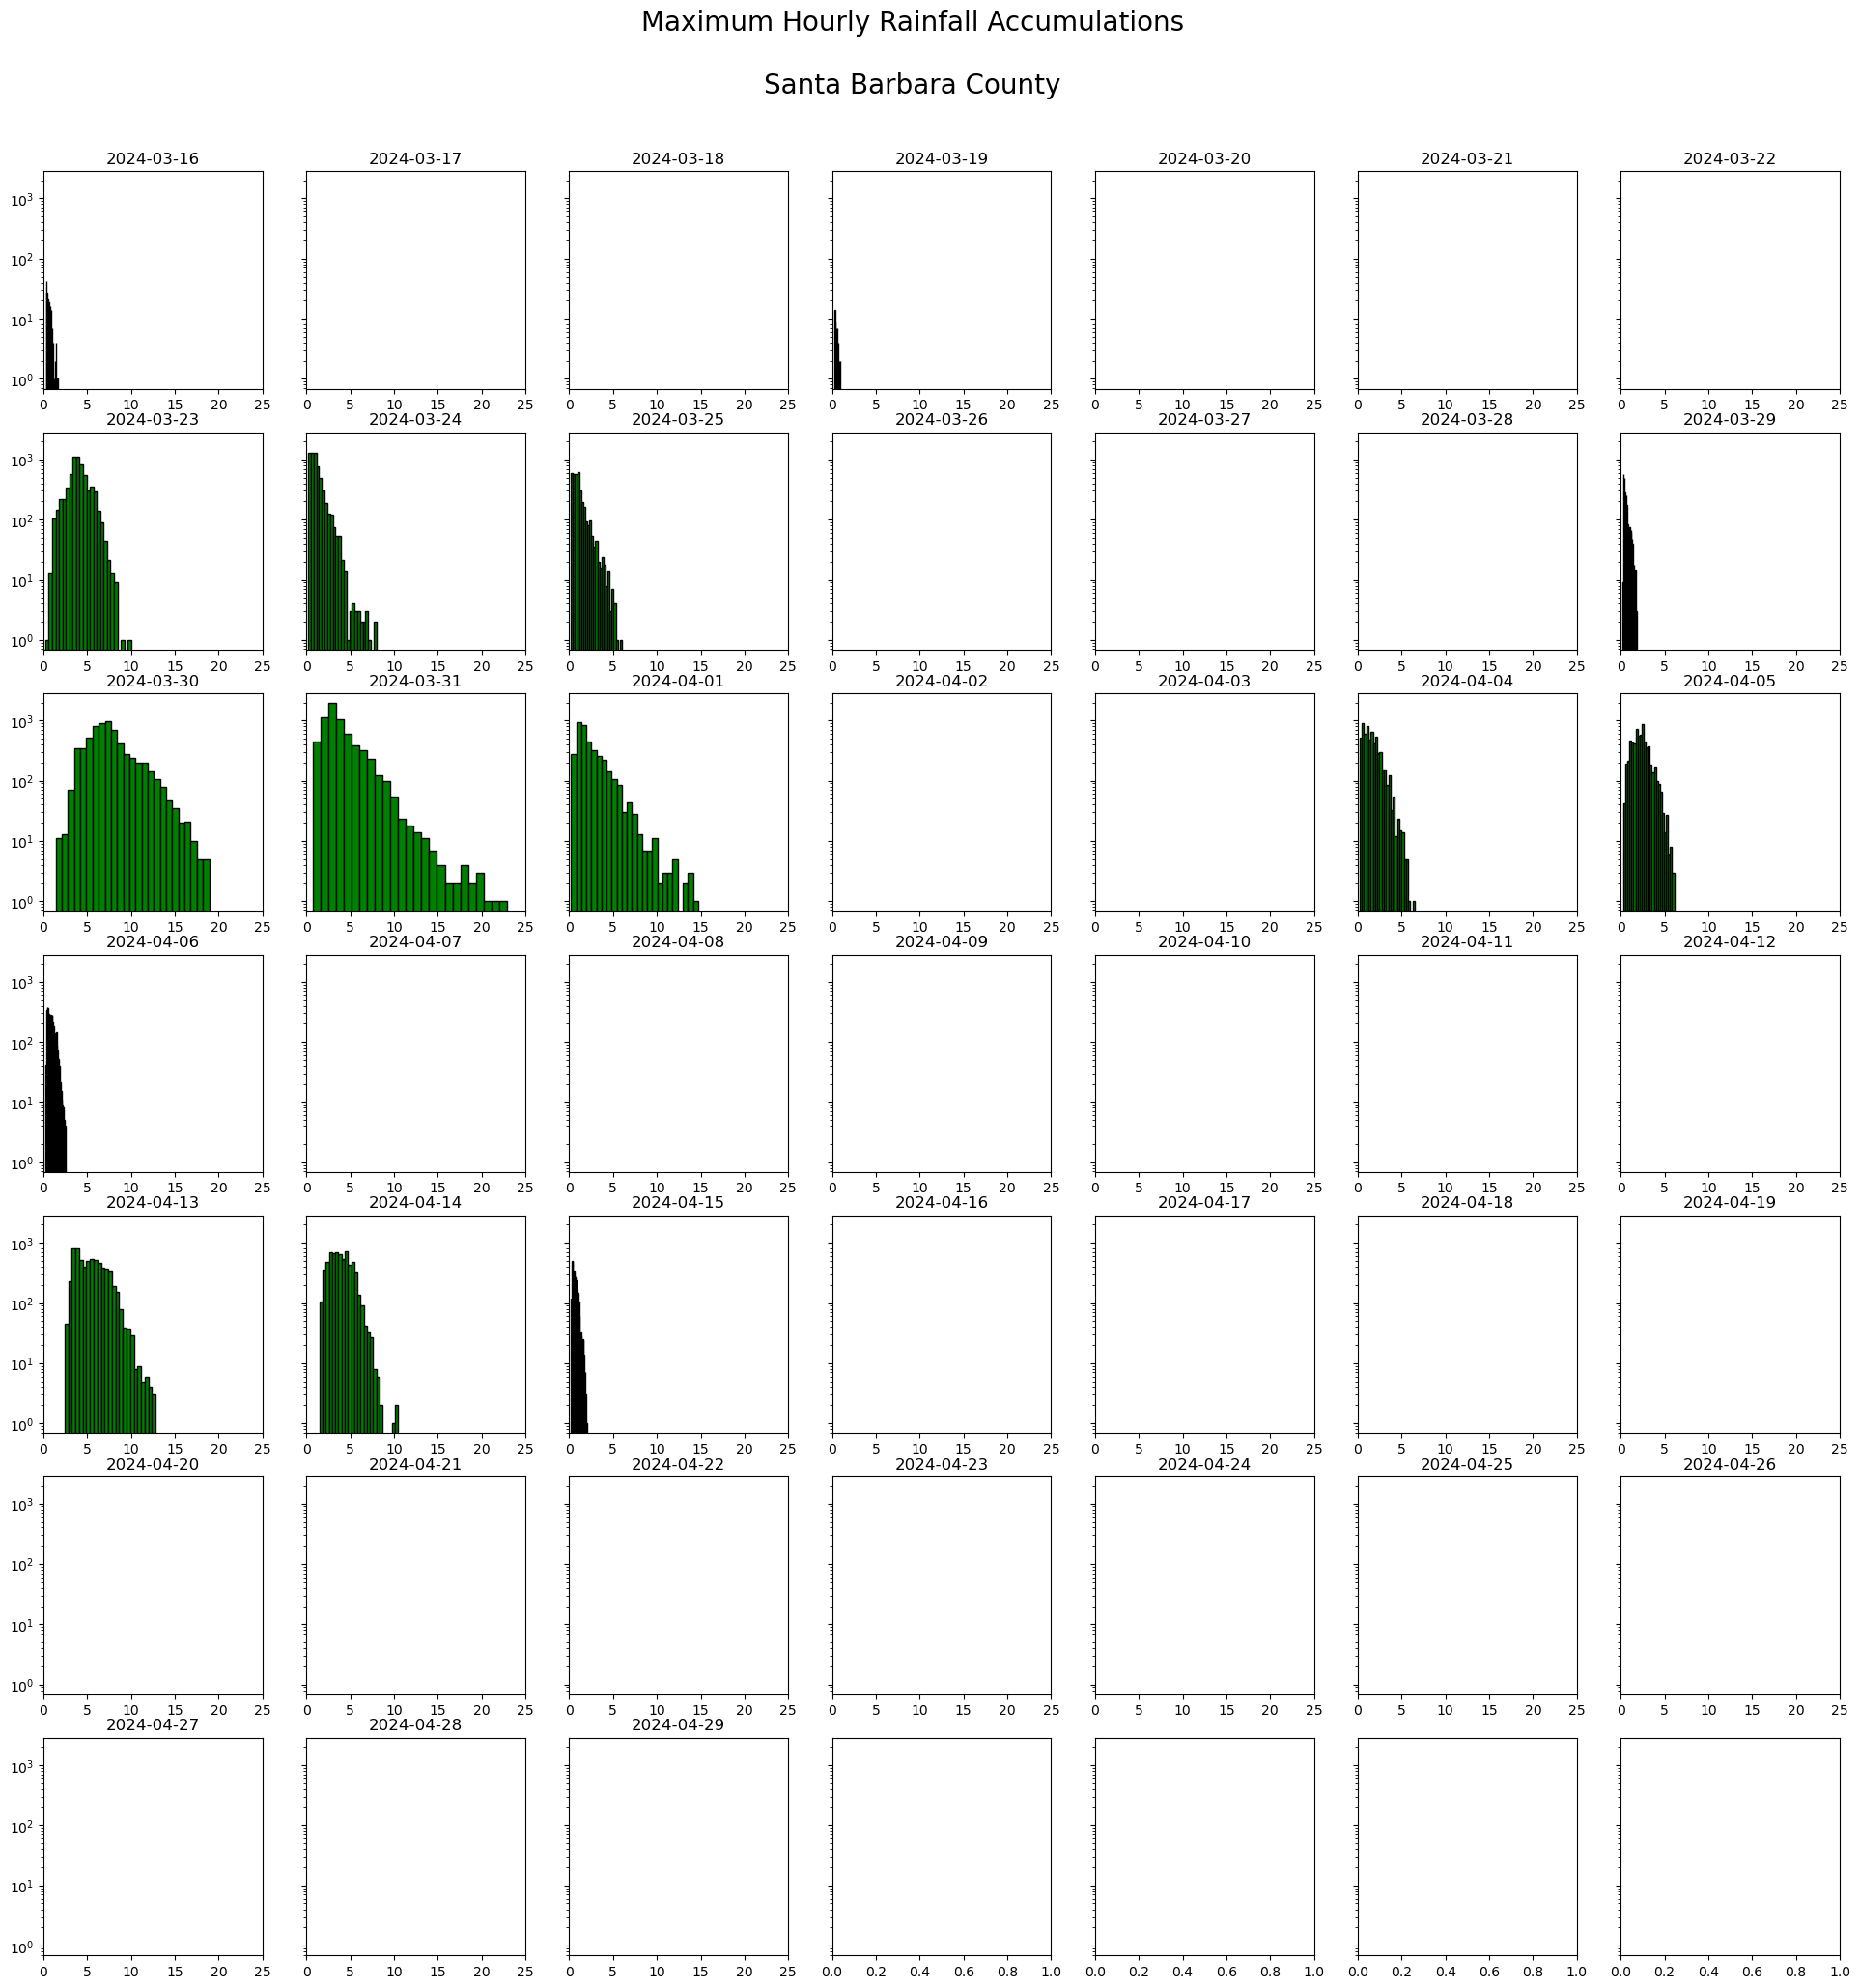

In [11]:
dates = pd.date_range("2024-03-16", "2024-04-29").strftime("%Y-%m-%d")
counties = ['Los Angeles', 'Ventura', 'Santa Barbara']
colors = ['dodgerblue', 'orange', 'green']
for j in range(3):
    fig, axes = plt.subplots(7, 7, figsize=(24, 24), sharey=True)
    for i, ax in enumerate(axes.ravel()):
        if i == 45:
            break
        data = masked_ds.groupby(masked_ds['time'].dt.date).max().sel(county=counties[j]).isel(date=i)['precip_acc_1h'].values.ravel()
        ax.hist(data[data > 0], bins=25, edgecolor='k', log=True, color=colors[j])
        ax.set_xlim(0, 25)
        ax.set_title(dates[i])
    fig.suptitle(f"Maximum Hourly Rainfall Accumulations\n\n{counties[j]} County", y=0.95,  fontsize=20)
# plt.show()

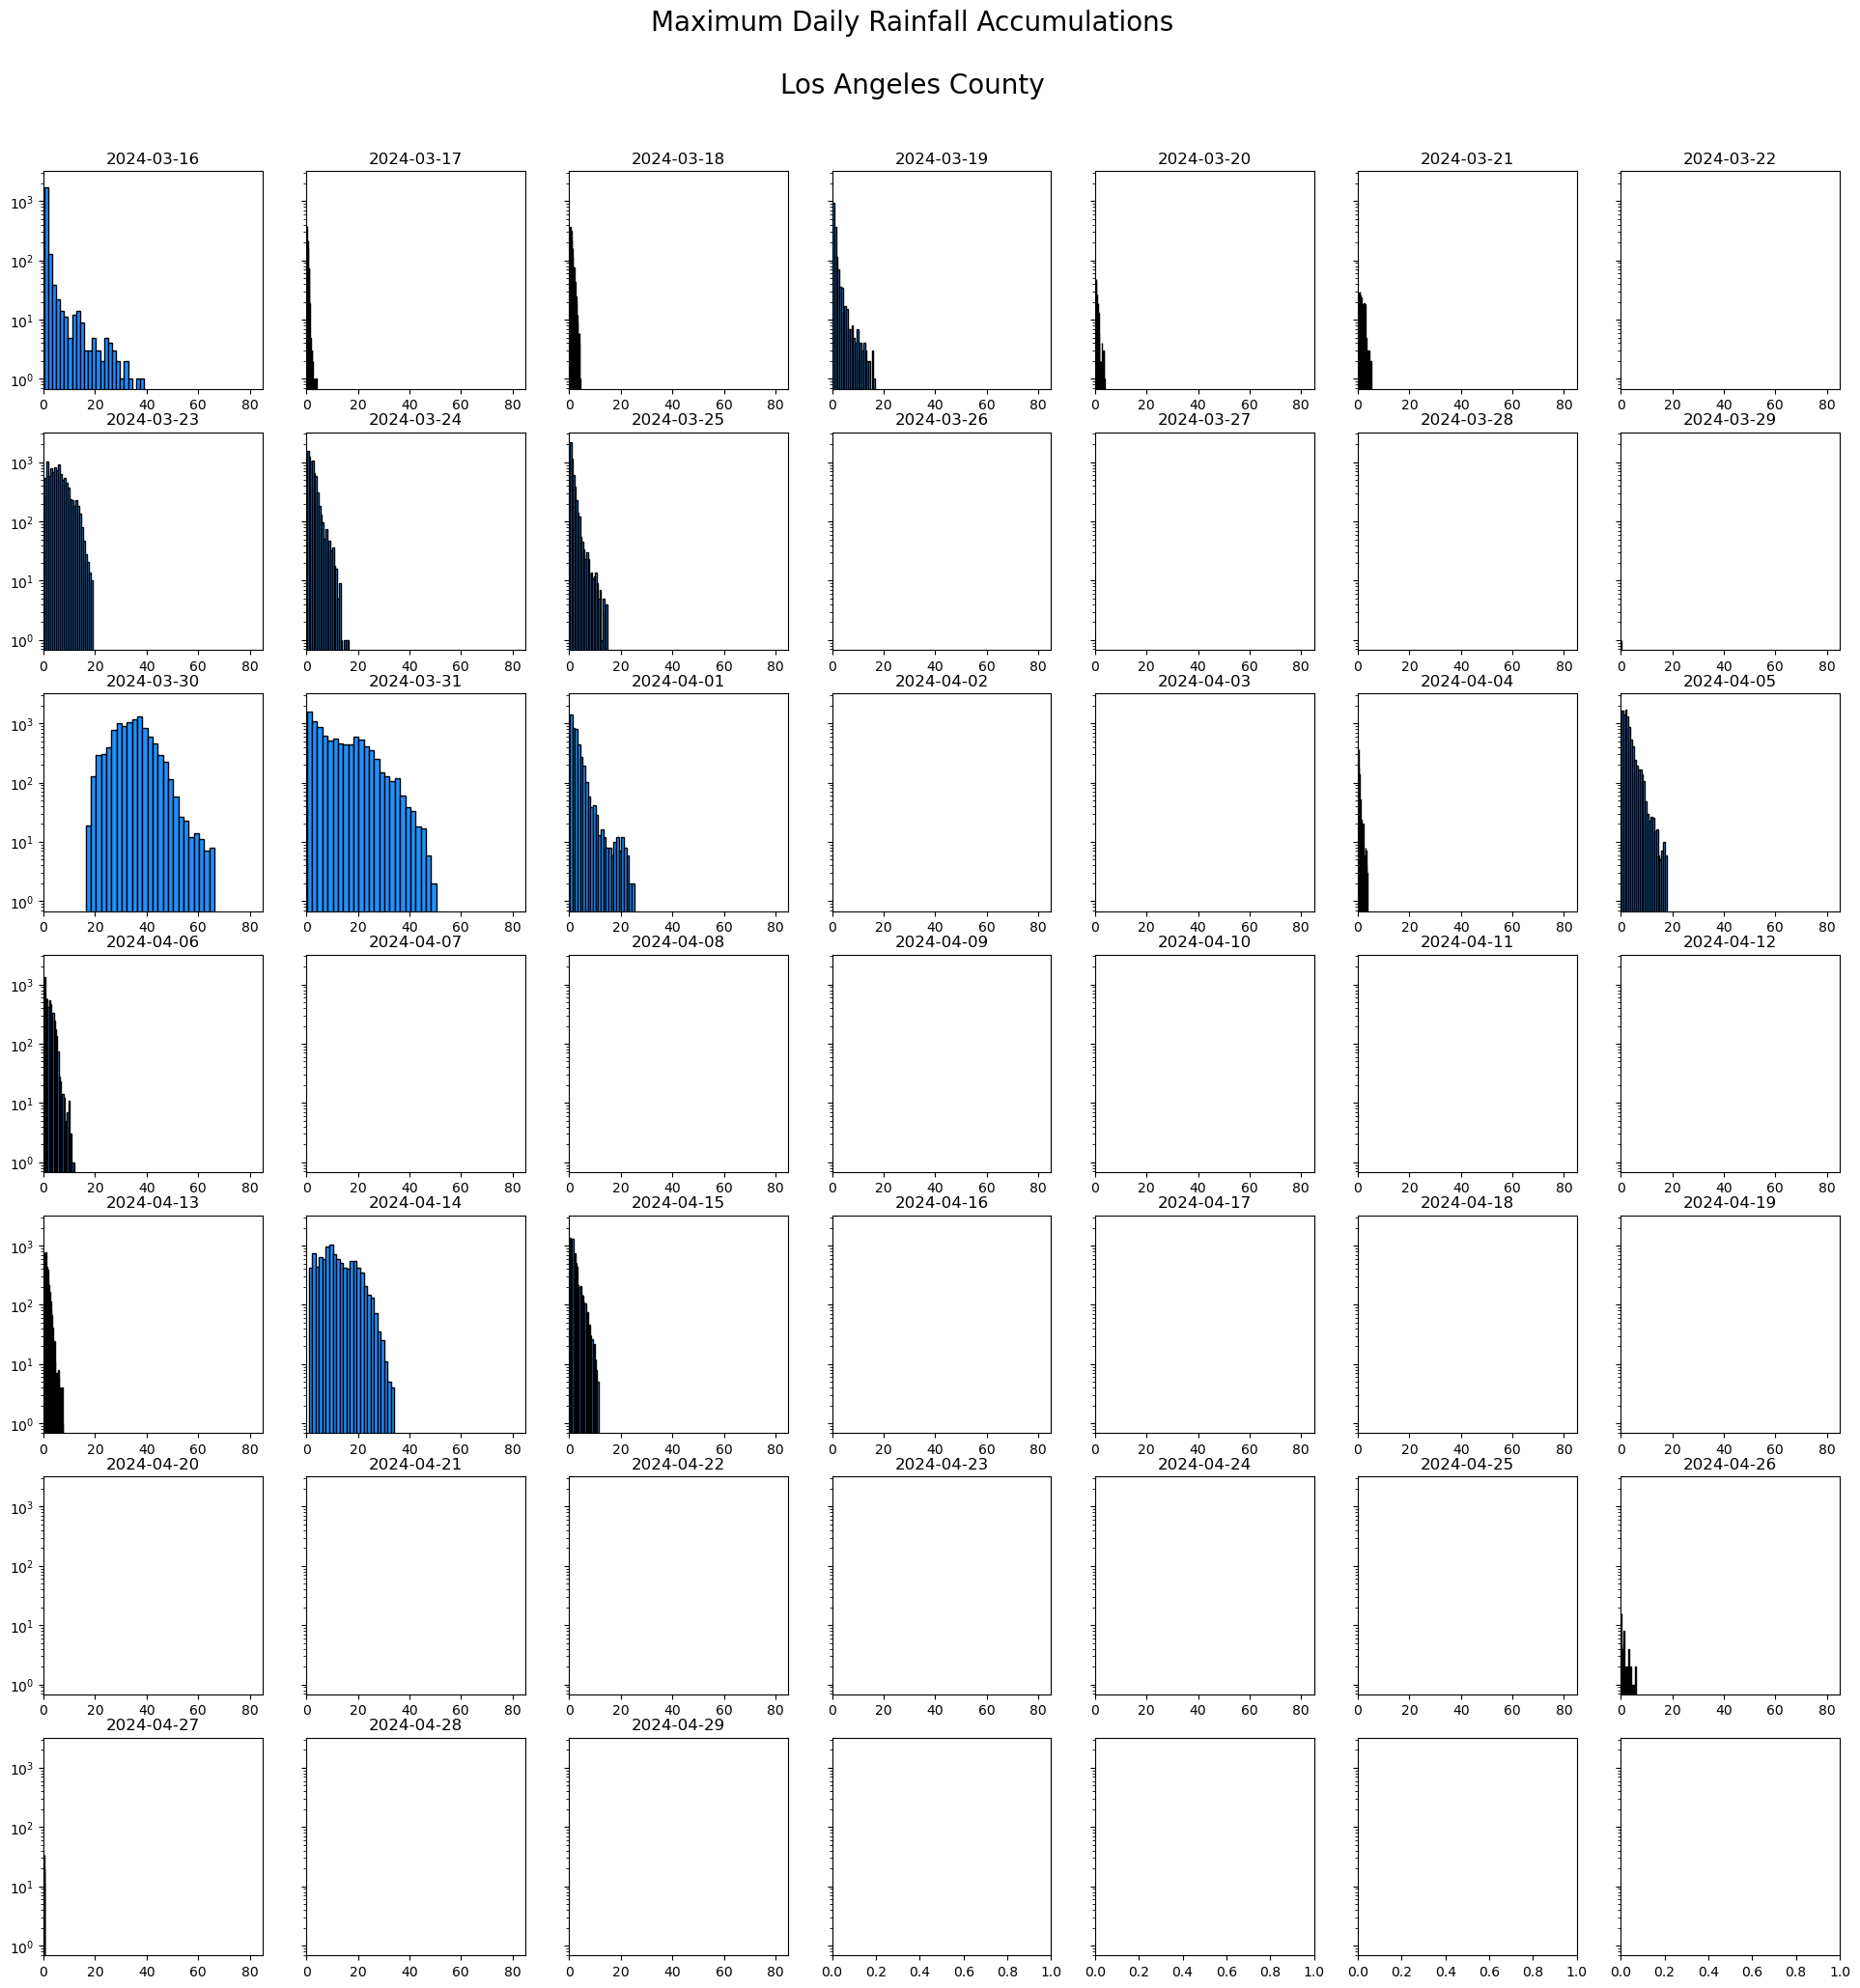

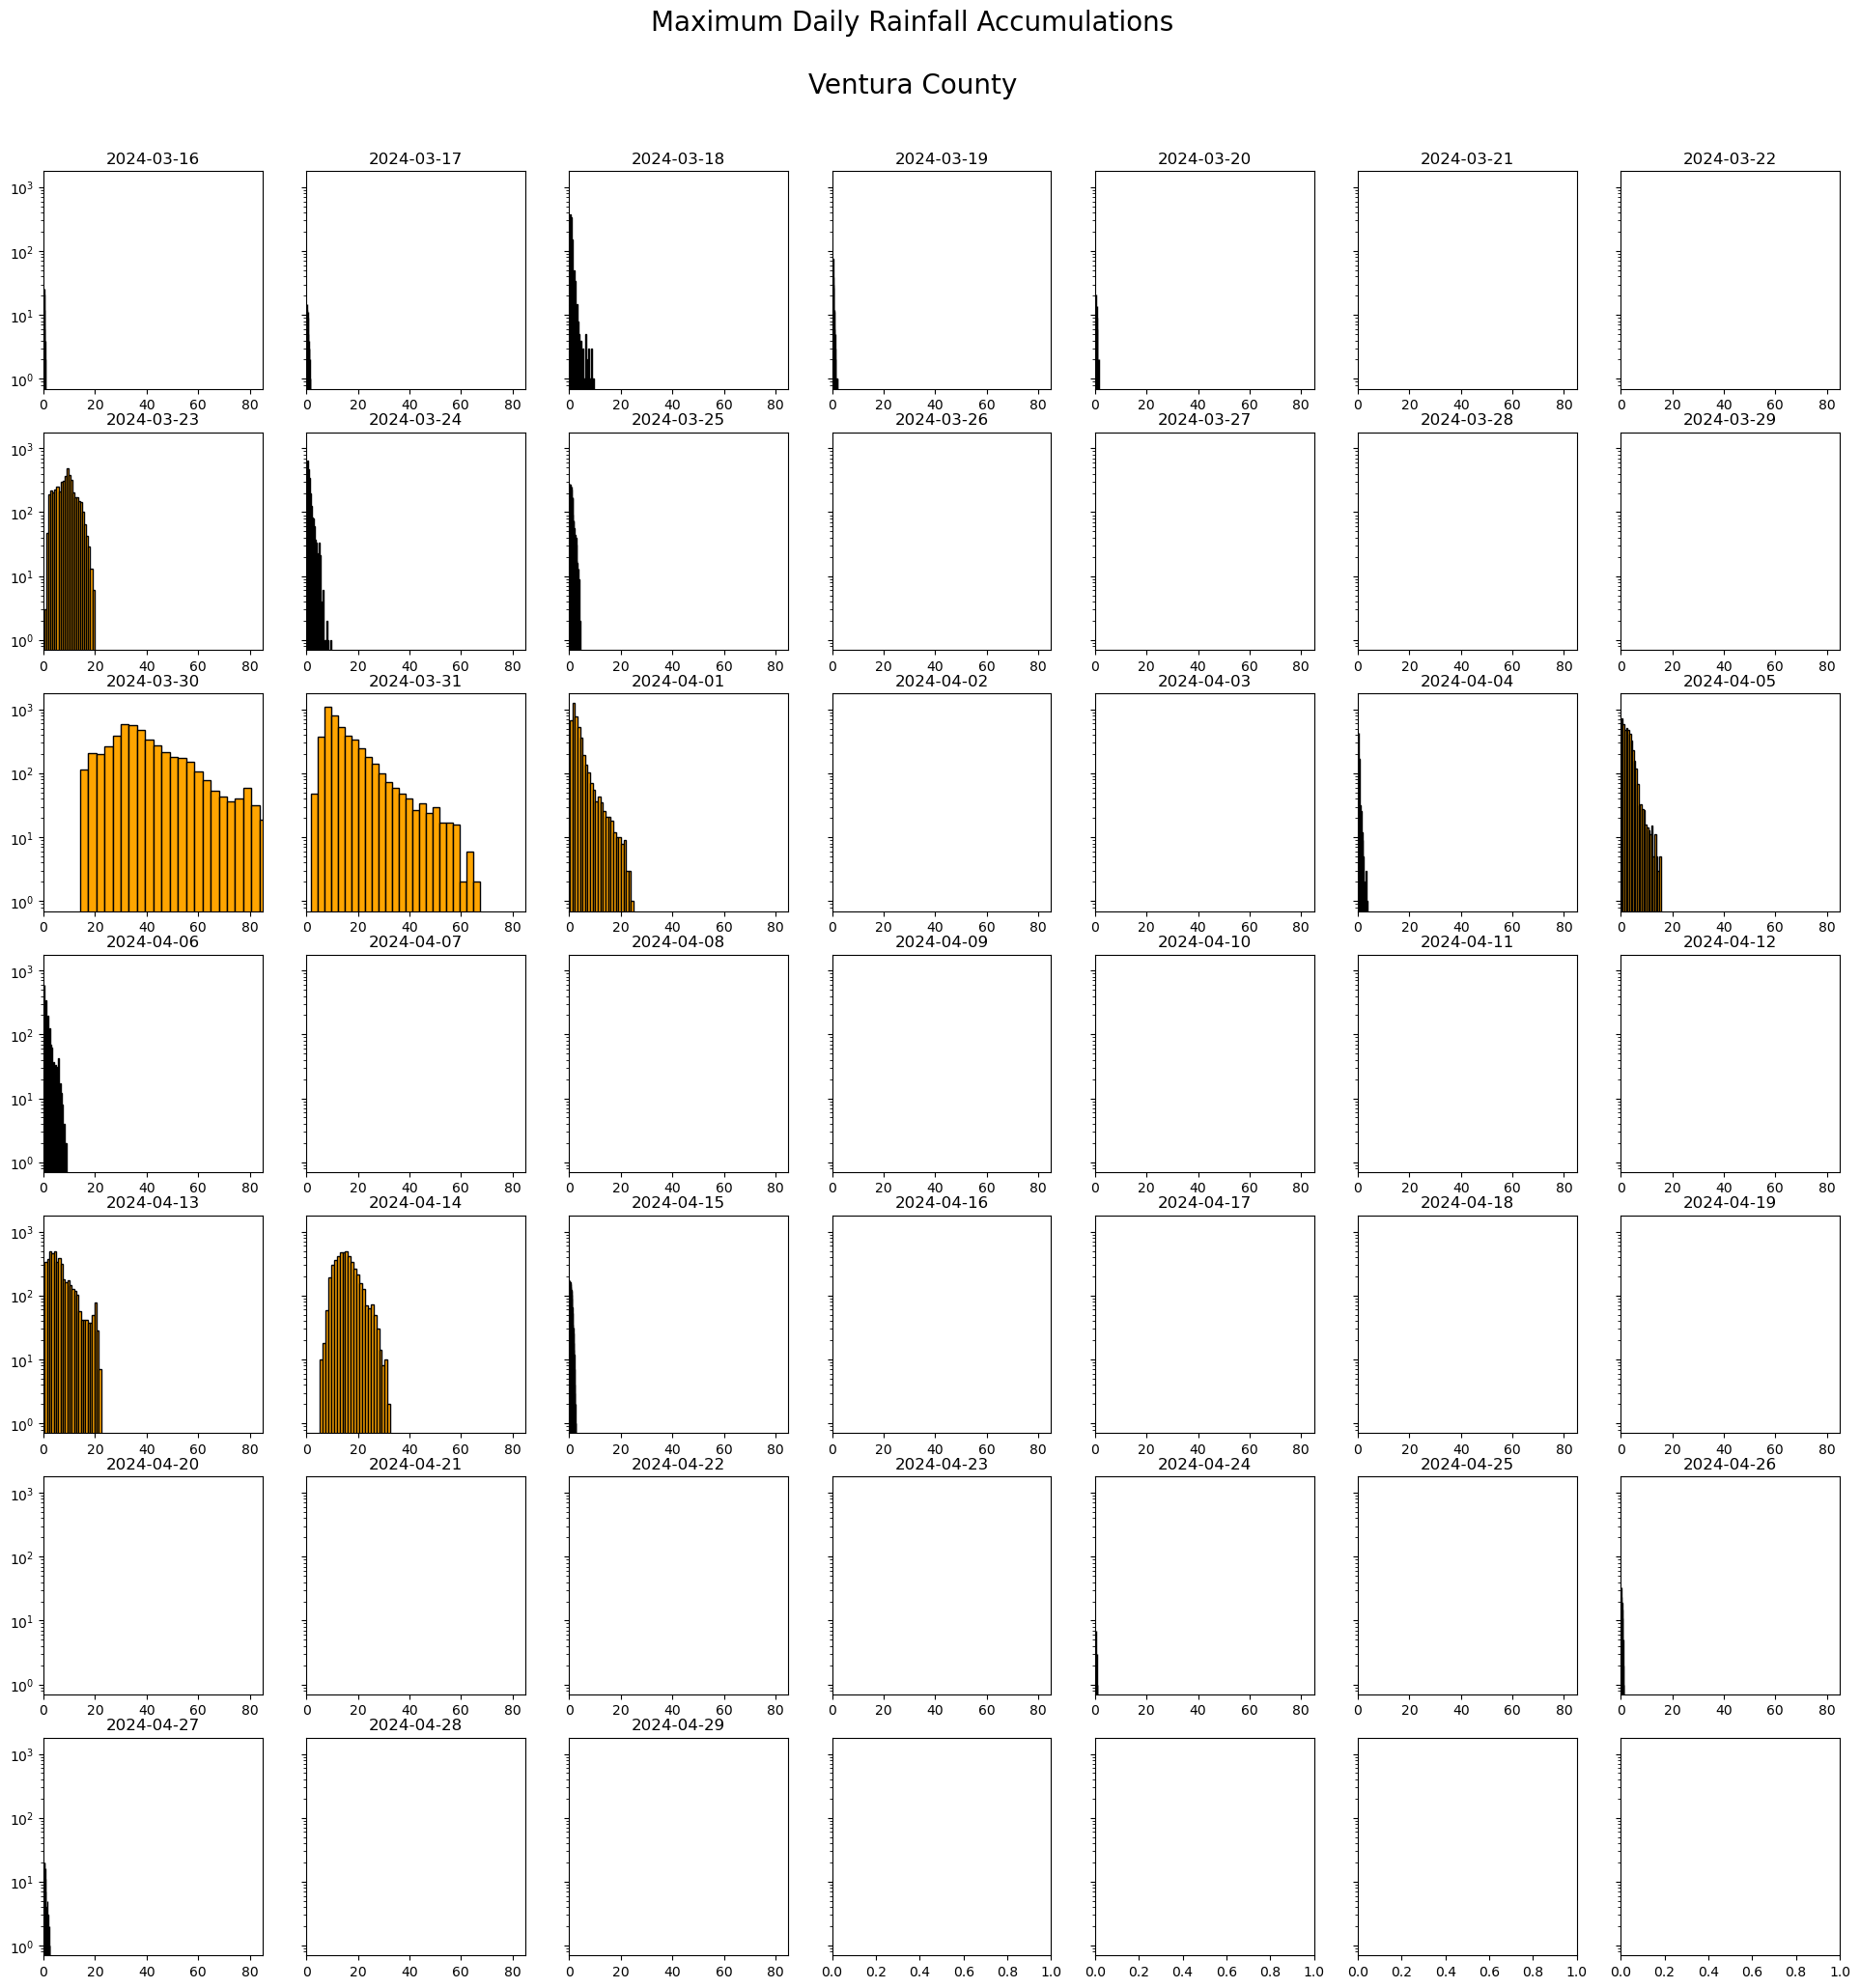

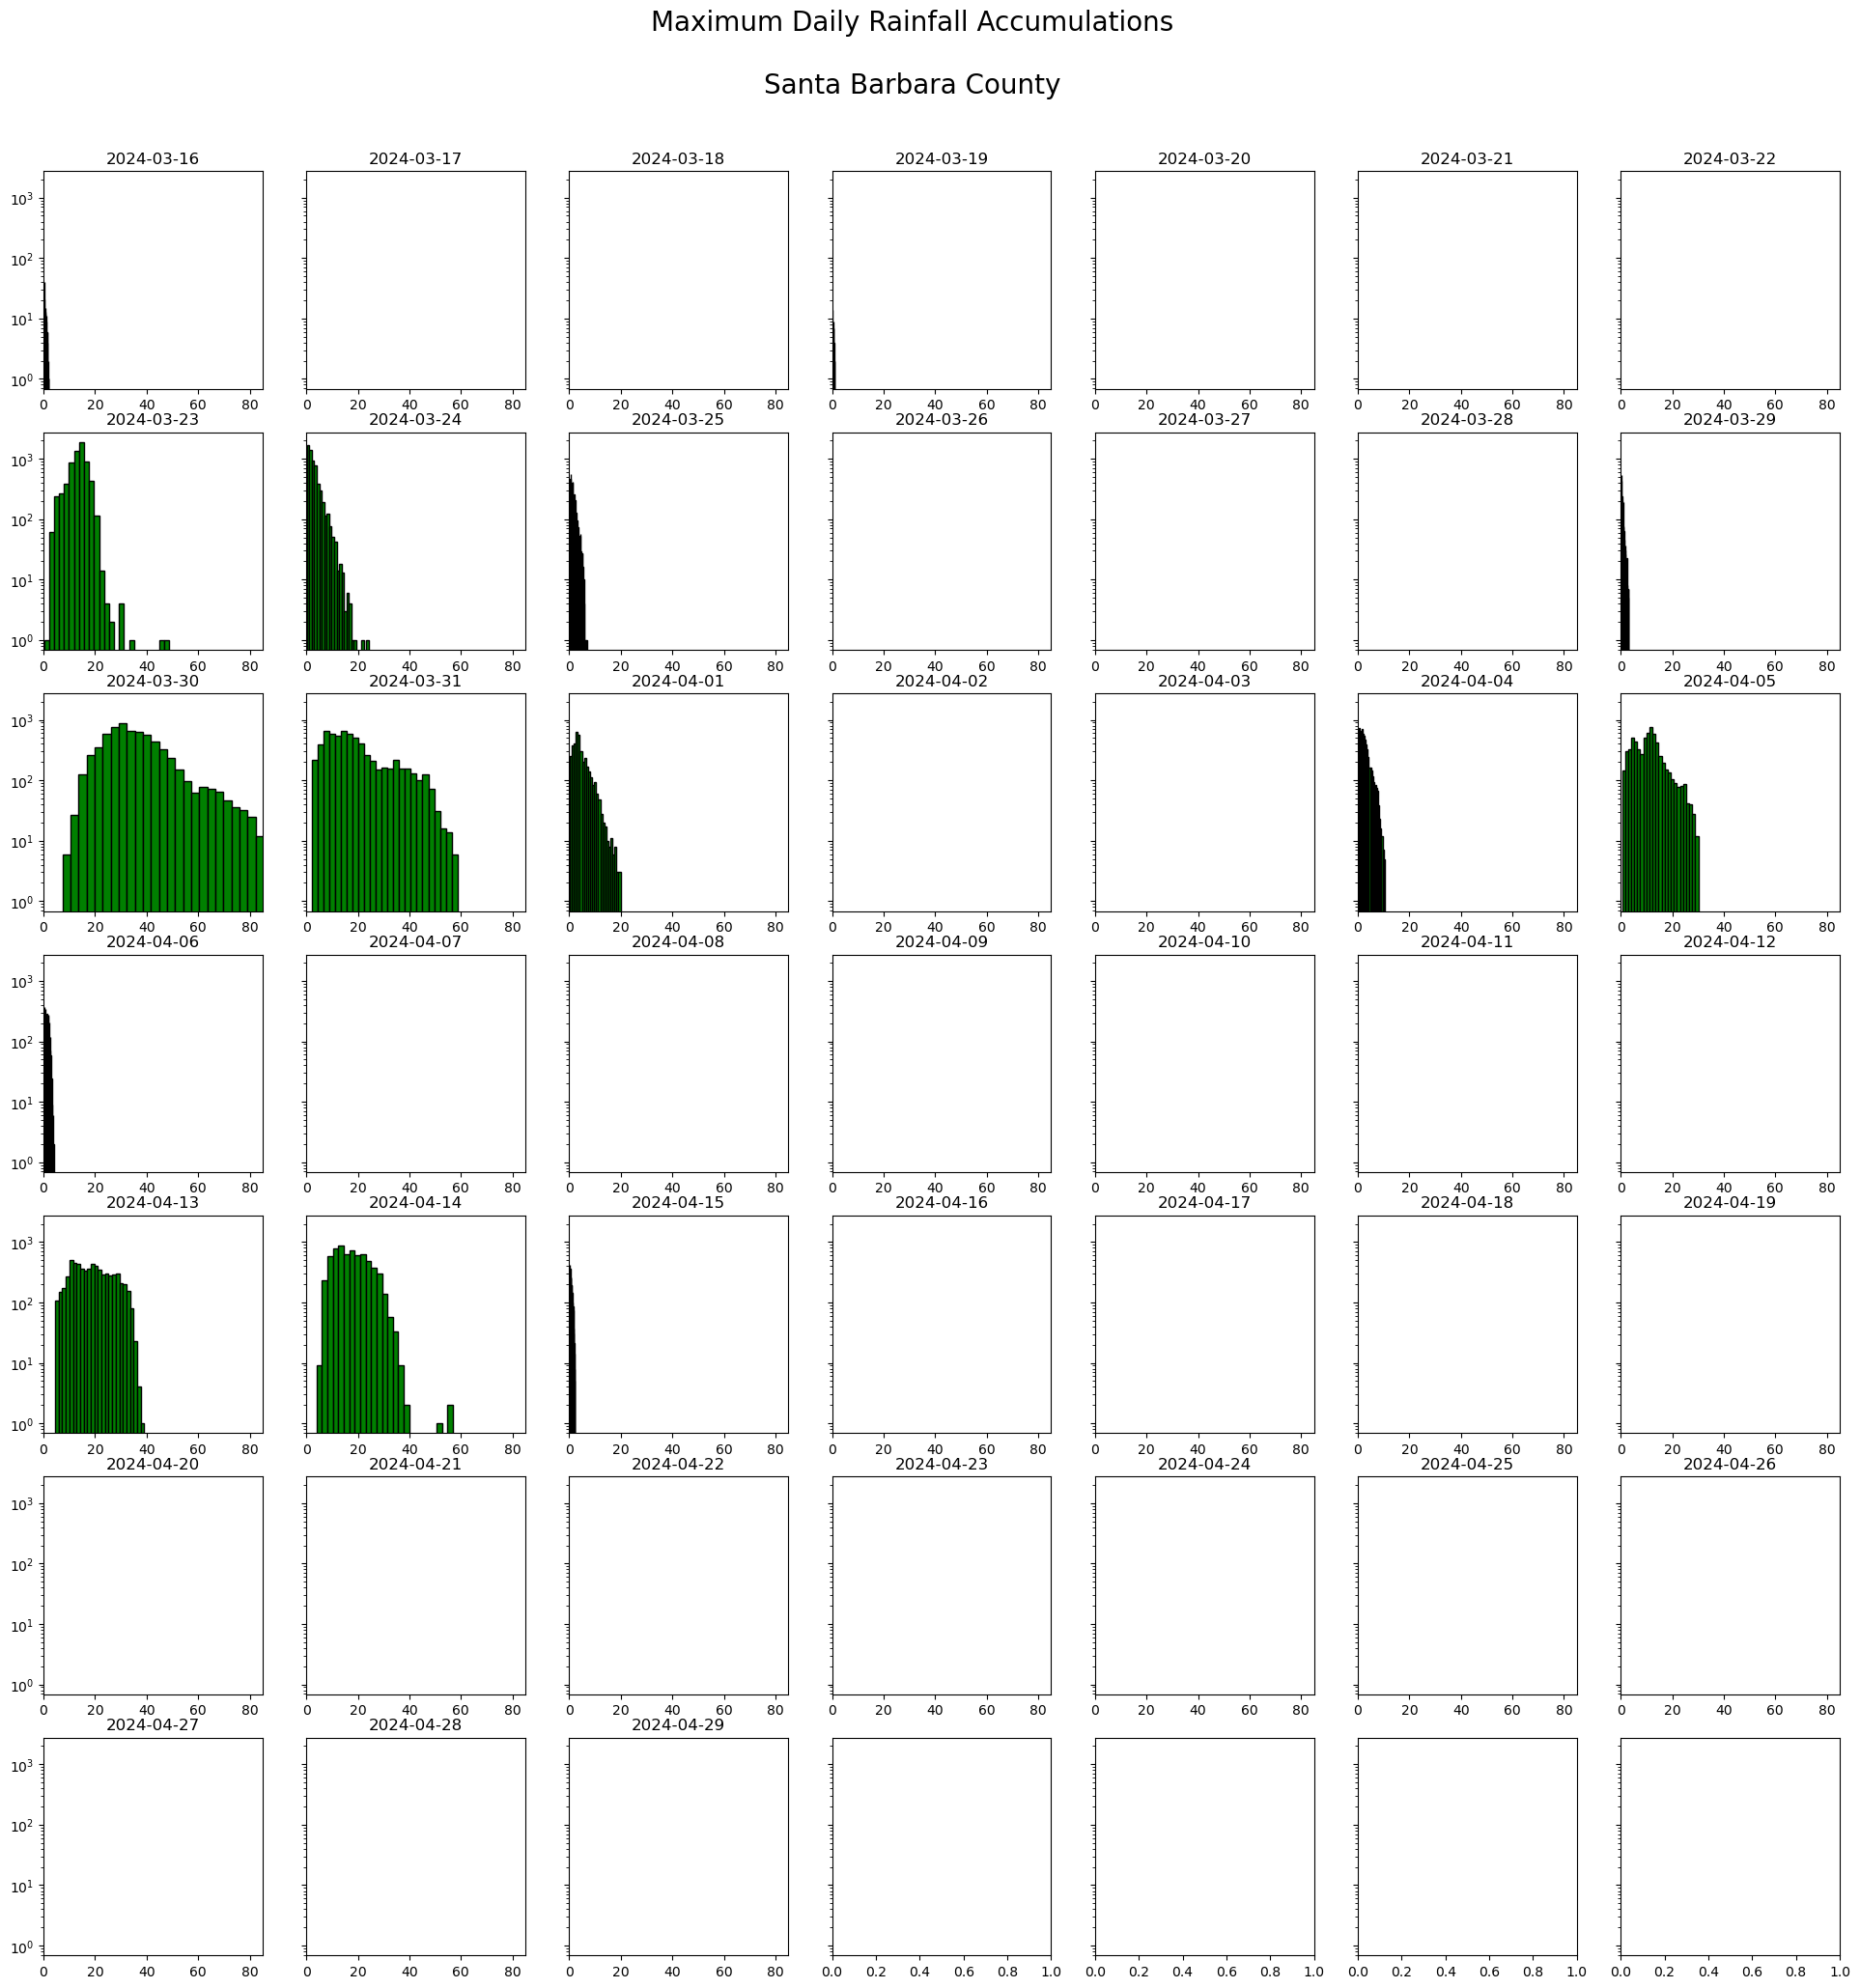

In [12]:
dates = pd.date_range("2024-03-16", "2024-04-29").strftime("%Y-%m-%d")
counties = ['Los Angeles', 'Ventura', 'Santa Barbara']
colors = ['dodgerblue', 'orange', 'green']
for j in range(3):
    fig, axes = plt.subplots(7, 7, figsize=(24, 24), sharey=True)
    for i, ax in enumerate(axes.ravel()):
        if i == 45:
            break
        data = masked_ds.groupby(masked_ds['time'].dt.date).sum().sel(county=counties[j]).isel(date=i)['precip_acc_1h'].values.ravel()
        ax.hist(data[data > 0], bins=25, edgecolor='k', log=True, color=colors[j])
        ax.set_xlim(0, 85)
        ax.set_title(dates[i])
    fig.suptitle(f"Maximum Daily Rainfall Accumulations\n\n{counties[j]} County", y=0.95,  fontsize=20)